# 03b. Exploratory analysis of the training set

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
P = ROOT / "data" / "processed"

lab = pl.read_parquet(P / "train_labeled.parquet").to_pandas()
tr = pl.read_parquet(P / "train_features.parquet").to_pandas()
base = tr["is_viral"].mean()
print("base viral rate:", round(base, 3))

base viral rate: 0.1


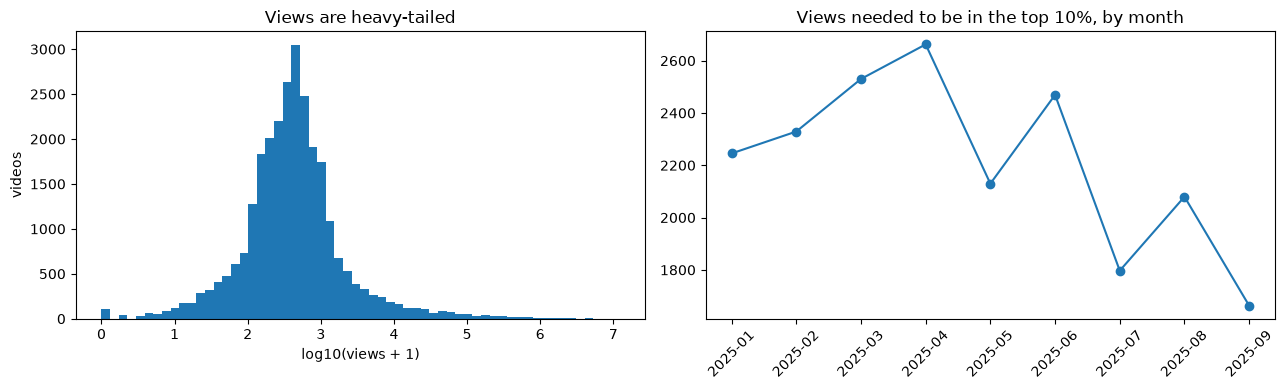

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(np.log10(lab["views"] + 1), bins=60)
ax[0].set_title("Views are heavy-tailed")
ax[0].set_xlabel("log10(views + 1)")
ax[0].set_ylabel("videos")

p90 = lab.groupby(lab["posted_at"].dt.strftime("%Y-%m"))["views"].quantile(0.9)
ax[1].plot(p90.index, p90.values, marker="o")
ax[1].set_title("Views needed to be in the top 10%, by month")
ax[1].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

### Interpretation: why a relative threshold

**Left (distribution).** The histogram of log10(views + 1) is centered around 2.5 to 3,
which means a typical video gets a few hundred to about a thousand views. The long right tail
reaches 10^6 and 10^7: a small number of videos get thousands of times more views than the
typical one. Raw views are therefore heavily skewed, and a plain average would be misleading.
The small spike at 0 corresponds to videos with no views.

**Right (monthly threshold).** The number of views needed to be in the top 10% is not constant.
It moves between about 1,700 and 2,700 across the months of the training period, with a
general downward trend toward September (the last month is also a partial month, so it
should be read with caution). A fixed threshold, for example 2,000 views, would label many
more videos as viral in some months than in others.

**Conclusion.** Both observations justify defining "viral" as the top 10% of views within
each posting month. This keeps the share of positives stable (about 10%) and prevents the
model from learning "posted in a certain month means viral".

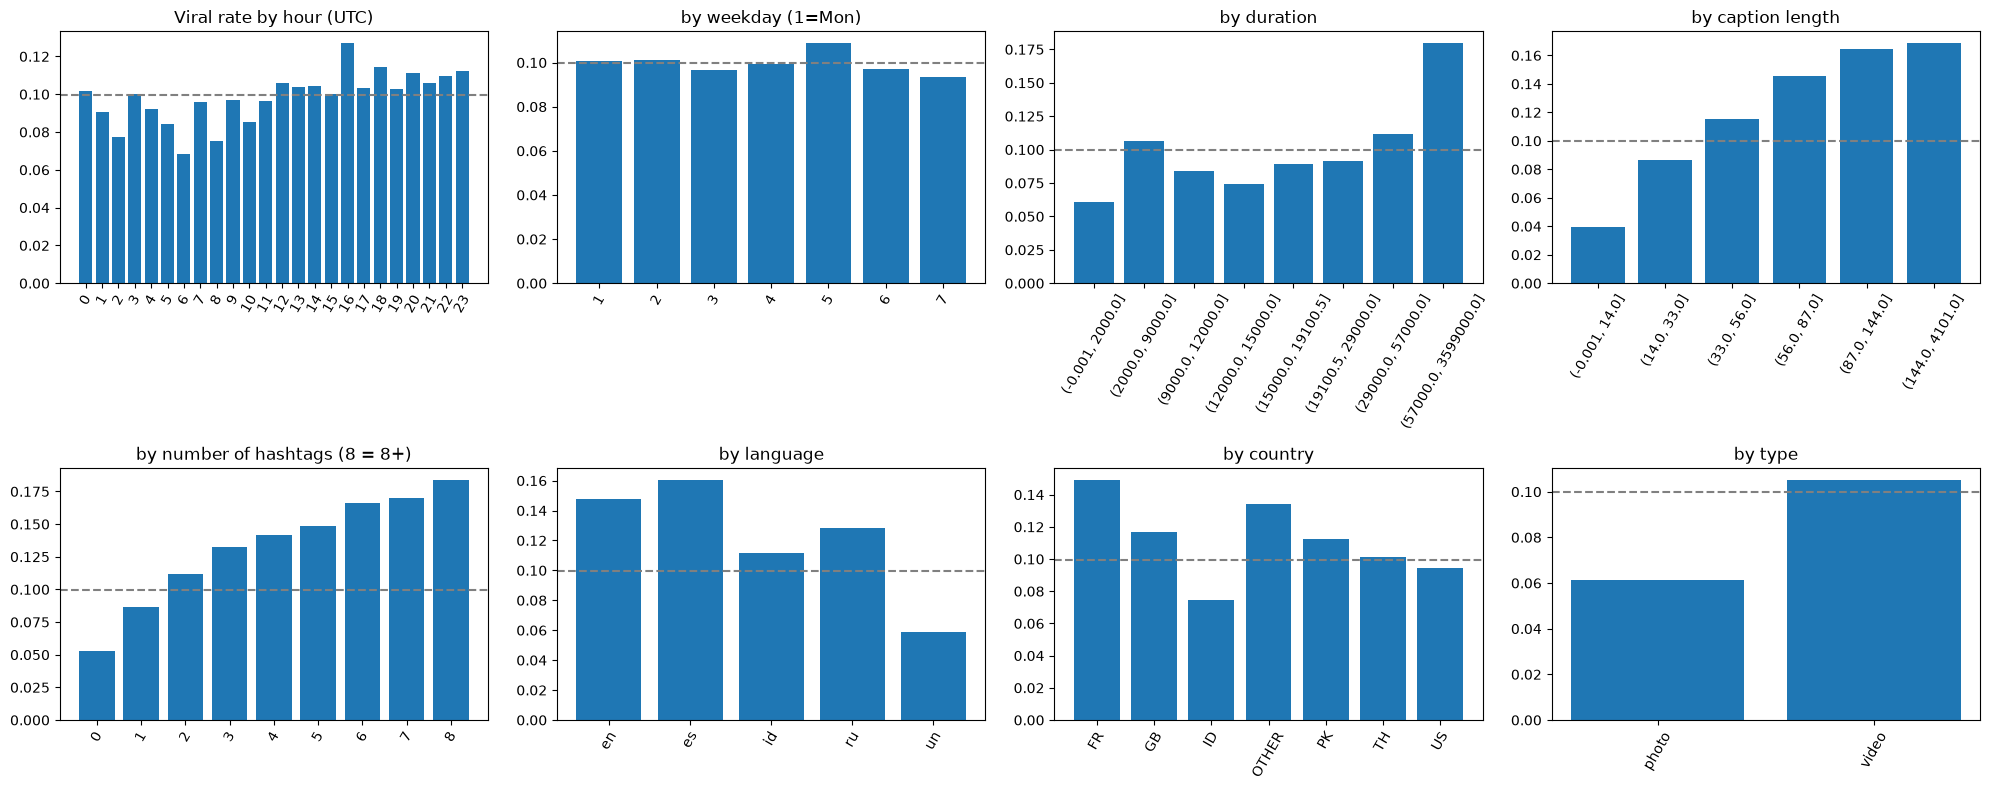

In [4]:
def rate_plot(ax, series, title, q=None, min_n=200):
    s = pd.qcut(series, q, duplicates="drop") if q else series
    g = tr.groupby(s, observed=True)["is_viral"].agg(["mean", "size"])
    g = g[g["size"] >= min_n]
    ax.bar(g.index.astype(str), g["mean"])
    ax.axhline(base, ls="--", color="gray")
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=60)

fig, axes = plt.subplots(2, 4, figsize=(20, 8))
rate_plot(axes[0, 0], tr["hour"], "Viral rate by hour (UTC)")
rate_plot(axes[0, 1], tr["weekday"], "by weekday (1=Mon)")
rate_plot(axes[0, 2], tr["duration_ms"], "by duration", q=8)
rate_plot(axes[0, 3], tr["caption_len"], "by caption length", q=8)
rate_plot(axes[1, 0], tr["n_hashtags"].clip(upper=8), "by number of hashtags (8 = 8+)")
rate_plot(axes[1, 1], tr["language"], "by language")
rate_plot(axes[1, 2], tr["country"], "by country")
rate_plot(axes[1, 3], tr["type"], "by type")
plt.tight_layout(); plt.show()

### Interpretation: which features are linked to virality

The dashed line is the overall viral rate (about 10%). A bar above it means that group is
more often viral than average, and a bar below it means less often.

**Strong signals**
- **Caption length:** the rate rises steadily from about 4% for very short captions to about
  17% for long ones. This is the clearest pattern.
- **Number of hashtags:** same steady rise, from about 5% with no hashtag to about 18% with
  8 or more.
- **Duration:** the highest rate (about 18%) is for the longest videos, and the lowest (about 6%)
  for the shortest. The middle ranges sit below average, so the link is not a straight line.
- **Type:** videos (about 10.5%) are viral more often than photo posts (about 6%).
- **Language:** videos with an unknown language ("un") are rarely viral (about 6%), while English
  and Spanish are above average (about 15% and 16%).

**Weaker signals**
- **Hour of posting:** the rate is lower at night and early morning UTC (about 7% to 9% around
  hours 2 to 8) and higher in the afternoon and evening (about 11% to 13%, with a peak at hour 16).
- **Country:** ID is below average (about 7.5%) while FR and the grouped small countries are
  above. The US, which holds most of the data, is slightly under 10%.
- **Weekday:** all bars are close to the line, so the day of the week carries almost no signal.

**Caution.** These are associations, not causes. Several features are related to each other:
a long caption often comes with many hashtags, and photo posts have no duration. Also, the
language and caption features are probably linked, since an unknown language often means an
empty or very short caption. We should not write that longer captions make videos viral.

**Link with the models.** This matches the importance table: caption length, duration and
hashtags are the most used features, and weekday is among the least. It also explains why
LightGBM beats logistic regression, since the duration effect is not a straight line.

In [7]:
print(tr[["caption_len", "n_hashtags", "duration_ms"]].corr(method="spearman").round(2))
print(tr.groupby("language")["caption_len"].median())

             caption_len  n_hashtags  duration_ms
caption_len         1.00        0.82         0.17
n_hashtags          0.82        1.00         0.15
duration_ms         0.17        0.15         1.00
language
af         46.0
am         41.5
ar         73.5
az         64.5
be         14.0
           ... 
xh         92.0
yo         40.5
zh-Hans    38.0
zh-Hant    92.0
zu         32.0
Name: caption_len, Length: 103, dtype: float64


Caption length and hashtags are almost the same signal. The Spearman correlation is 0.82, which is very high. Hashtags are usually written inside the caption text, so a long caption tends to contain many hashtags. In the earlier graph, caption length and hashtag count both showed a steady rise in viral rate, but that is probably one effect seen twice, not two independent effects.

Duration is mostly separate. Its correlations with the other two are only 0.17 and 0.15, so it carries its own information. That is good news for the model.

The language output is not useful as printed. There are 103 languages, and pandas hides most of the rows. What I wanted to check is whether the unknown language (“un”) goes with empty or very short captions.

In [8]:
tr["is_un"] = tr["language"] == "un"
print(tr.groupby("is_un")["caption_len"].agg(["median", "mean"]).round(1))
print("share of empty captions, un vs known:")
print(tr.groupby("is_un")["caption_len"].apply(lambda s: (s == 0).mean()).round(3))

       median   mean
is_un               
False    83.0  129.6
True      0.0   23.6
share of empty captions, un vs known:
is_un
False    0.004
True     0.504
Name: caption_len, dtype: float64


In [9]:
tr["len_band"] = pd.qcut(tr["caption_len"], 4, duplicates="drop")
tr["tag_band"] = pd.cut(tr["n_hashtags"], [-1, 0, 2, 5, 100], labels=["0", "1-2", "3-5", "6+"])
tab = tr.pivot_table(index="len_band", columns="tag_band", values="is_viral",
                     aggfunc="mean", observed=True)
print(tab.round(3))
print(tr.pivot_table(index="len_band", columns="tag_band", values="is_viral",
                     aggfunc="size", observed=True))

tag_band            0    1-2    3-5     6+
len_band                                  
(-0.001, 33.0]  0.044  0.074  0.090  0.200
(33.0, 87.0]    0.112  0.124  0.136  0.150
(87.0, 4101.0]  0.119  0.136  0.156  0.182
tag_band            0   1-2   3-5    6+
len_band                               
(-0.001, 33.0]  10887  2466   423    35
(33.0, 87.0]     1085  1713  3477   645
(87.0, 4101.0]    469   428  2187  3767


### Interpretation: overlap between caption, hashtags and language

**Unknown language.** Videos with language "un" have a median caption length of 0, and 50.4%
of them have an empty caption (versus 0.4% for known languages). So "un" mostly means
"no text to analyze". Its low viral rate (about 6%) is largely the short-caption effect again,
not a language effect.

**Hashtags beyond caption length.** Within each caption-length band, the viral rate still rises
with the number of hashtags (for example 11.2% with 0 tags to 15.0% with 6+ in medium captions,
and 11.9% to 18.2% in long captions). So hashtags add some information beyond caption length,
but less than the raw graph suggested, because part of that effect was caption length itself.
The cell for short captions with 6+ hashtags has only 35 videos, so its 20% rate is not reliable.

**Consequence for modeling.** Keep `caption_len`, `n_hashtags` and `language`, but do not
interpret their importance separately. Drop `caption_words`, which duplicates `caption_len`.
These are associations, not causes.